In [3]:
!wget -O /kaggle/working/Dataset_Exercise-wise.zip "https://data.mendeley.com/public-files/datasets/kgbb3yn47p/files/2499db21-0988-42a4-b068-0e79a8a3c51a/file_downloaded"

--2026-09-30 14:07:07--  https://data.mendeley.com/public-files/datasets/kgbb3yn47p/files/2499db21-0988-42a4-b068-0e79a8a3c51a/file_downloaded
Resolving data.mendeley.com (data.mendeley.com)... 162.159.130.86, 162.159.133.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.130.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/37e8189b-f27f-4093-877a-9a1fb11dc57e [following]
--2026-09-30 14:07:08--  https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/37e8189b-f27f-4093-877a-9a1fb11dc57e
Resolving prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)... 3.5.75.76, 3.5.64.233, 3.5.69.12, ...
Connecting to prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)|3.5.75.76|:443... connect

In [ ]:
!unzip -q /kaggle/working/Dataset_Exercise-wise.zip -d /kaggle/working/dataset

In [17]:
import os

dataset_path = "/kaggle/working/dataset"

print(os.listdir(dataset_path))

['Dataset Exercise Quality-wise']


In [21]:
import os

base = "/kaggle/working/dataset/Dataset Exercise Quality-wise/push_up"

for label in ["good", "bad"]:
    for view in ["front", "side", "diagonal"]:
        path = os.path.join(base, label, view)
        files = os.listdir(path)

        print(f"{label}/{view}: {len(files)} files")
        print(files[:3])
        print()

good/front: 24 files
['subject_004_push_up_good_front.mp4', 'subject_006_push_up_good_front.mp4', 'subject_016_push_up_good_front.mp4']

good/side: 24 files
['subject_009_push_up_good_side.mp4', 'subject_019_push_up_good_side.mp4', 'subject_007_push_up_good_side.mp4']

good/diagonal: 24 files
['subject_016_push_up_good_diagonal.mp4', 'subject_004_push_up_good_diagonal.mp4', 'subject_010_push_up_good_diagonal.mp4']

bad/front: 24 files
['subject_012_push_up_bad_front.mp4', 'subject_006_push_up_bad_front.mp4', 'subject_004_push_up_bad_front.mp4']

bad/side: 24 files
['subject_008_push_up_bad_side.mp4', 'subject_002_push_up_bad_side.mp4', 'subject_015_push_up_bad_side.mp4']

bad/diagonal: 24 files
['subject_019_push_up_bad_diagonal.mp4', 'subject_011_push_up_bad_diagonal.mp4', 'subject_001_push_up_bad_diagonal.mp4']



In [22]:
import cv2

video_path = "/kaggle/working/dataset/Dataset Exercise Quality-wise/push_up/good/front/subject_004_push_up_good_front.mp4"

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = frame_count / fps if fps > 0 else 0

print("FPS:", fps)
print("Frames:", frame_count)
print("Resolution:", width, "x", height)
print("Duration:", round(duration, 2), "seconds")

cap.release()

FPS: 15.0
Frames: 292
Resolution: 810 x 1440
Duration: 19.47 seconds


Biết được FPS, Frames 
Để biến video thành input cho model 

144 video
   ↓
Video frames
   ↓
Pose Estimation
   ↓
Skeleton / Keypoints
   ↓
Normalize
   ↓
Fixed-length sequence
   ↓
LSTM
   ↓
ST-GCN
   ↓
Good / Bad

In [1]:
!pip install mediapipe -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.9/37.9 MB 46.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 4.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [2]:
import sys

print(sys.version)
print(sys.executable)

3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
/usr/bin/python3


In [4]:
!python -m pip install mediapipe -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.9/37.9 MB 42.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 3.5 MB/s eta 0:00:00ta 0:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [6]:
import mediapipe as mp

print(mp.__version__)
print(hasattr(mp, "solutions"))

1.0.1
False


In [7]:
!wget -O /kaggle/working/pose_landmarker_full.task \
"https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task"

--2026-10-01 08:52:10--  https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task
Resolving storage.googleapis.com (storage.googleapis.com)... 64.233.181.207, 192.179.16.207, 74.125.69.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|64.233.181.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 9398198 (9.0M) [application/octet-stream]
Saving to: ‘/kaggle/working/pose_landmarker_full.task’

/kaggle/working/pos 100%[===================>]   8.96M  --.-KB/s    in 0.1s    

2026-10-01 08:52:10 (90.6 MB/s) - ‘/kaggle/working/pose_landmarker_full.task’ saved [9398198/9398198]



In [9]:
import mediapipe as mp

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

print("MediaPipe:", mp.__version__)
print("PoseLandmarker:", vision.PoseLandmarker)

MediaPipe: 1.0.1
PoseLandmarker: <class 'mediapipe.tasks.python.vision.pose_landmarker.PoseLandmarker'>


In [15]:
import cv2
import os

video_path = (
    "/kaggle/working/dataset/"
    "Dataset Exercise Quality-wise/"
    "push_up/good/front/"
    "subject_004_push_up_good_front.mp4"
)

print("File exists:", os.path.exists(video_path))

if os.path.exists(video_path):
    print("File size:", os.path.getsize(video_path) / (1024 * 1024), "MB")

    cap = cv2.VideoCapture(video_path)

    print("Video opened:", cap.isOpened())
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))
    print("Frames:", cap.get(cv2.CAP_PROP_FRAME_COUNT))

    ret, frame = cap.read()

    print("First frame read:", ret)

    if ret:
        print("Frame shape:", frame.shape)

    cap.release()

File exists: False


In [16]:
import glob

files = glob.glob(
    "/kaggle/working/dataset/"
    "Dataset Exercise Quality-wise/"
    "push_up/good/front/*"
)

print("Number of files:", len(files))

for f in files[:10]:
    print(f)

Number of files: 0


In [18]:
!ls -lah /kaggle/working

total 9.0M
drwxr-xr-x 3 root root 4.0K Oct  1 08:52 .
drwxr-xr-x 5 root root 4.0K Oct  1 08:48 ..
-rw-r--r-- 1 root root 9.0M Apr 28  2023 pose_landmarker_full.task
drwxr-xr-x 2 root root 4.0K Oct  1 08:48 .virtual_documents


In [19]:
!wget -O /kaggle/working/Dataset_Exercise-wise.zip \
"https://data.mendeley.com/public-files/datasets/kgbb3yn47p/files/2499db21-0988-42a4-b068-0e79a8a3c51a/file_downloaded"

--2026-10-01 09:02:44--  https://data.mendeley.com/public-files/datasets/kgbb3yn47p/files/2499db21-0988-42a4-b068-0e79a8a3c51a/file_downloaded
Resolving data.mendeley.com (data.mendeley.com)... 162.159.133.86, 162.159.130.86
Connecting to data.mendeley.com (data.mendeley.com)|162.159.133.86|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/37e8189b-f27f-4093-877a-9a1fb11dc57e [following]
--2026-10-01 09:02:45--  https://prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com/37e8189b-f27f-4093-877a-9a1fb11dc57e
Resolving prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)... 3.5.74.117, 52.92.0.66, 3.5.64.236, ...
Connecting to prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com (prod-dcd-datasets-public-files-eu-west-1.s3.eu-west-1.amazonaws.com)|3.5.74.117|:443... conn

In [20]:
!ls -lh /kaggle/working/Dataset_Exercise-wise.zip

-rw-r--r-- 1 root root 2.9G Aug 10 18:29 /kaggle/working/Dataset_Exercise-wise.zip


In [21]:
!mkdir -p /kaggle/working/dataset

!unzip -q /kaggle/working/Dataset_Exercise-wise.zip \
-d /kaggle/working/dataset

In [22]:
!find /kaggle/working/dataset -type f | head -20

/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_009_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_008_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_020_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_023_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_007_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_019_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_011_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_005_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_022_squat_bad_diagonal.mp4
/kaggle/working/dataset/Data

In [23]:
import os
import glob

video_files = glob.glob(
    "/kaggle/working/dataset/**/*.mp4",
    recursive=True
)

print("Total videos:", len(video_files))

for f in video_files[:10]:
    print(f)

Total videos: 1042
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_009_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_008_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_020_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_023_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_007_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_019_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_011_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_005_squat_bad_diagonal.mp4
/kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_022_squat_bad_diagonal.mp4
/kaggle/w

In [24]:
import cv2

video_path = video_files[0]

print("Video:", video_path)

cap = cv2.VideoCapture(video_path)

print("Opened:", cap.isOpened())
print("FPS:", cap.get(cv2.CAP_PROP_FPS))
print("Frames:", cap.get(cv2.CAP_PROP_FRAME_COUNT))

ret, frame = cap.read()

print("First frame:", ret)

if ret:
    print("Shape:", frame.shape)

cap.release()

Video: /kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_009_squat_bad_diagonal.mp4
Opened: True
FPS: 15.0
Frames: 456.0
First frame: True
Shape: (960, 540, 3)


In [25]:
import cv2
import numpy as np
import mediapipe as mp

from mediapipe.tasks import python
from mediapipe.tasks.python import vision


# =========================
# 1. Paths
# =========================

model_path = "/kaggle/working/pose_landmarker_full.task"

video_path = video_files[0]

print("Video:", video_path)


# =========================
# 2. Create Pose Landmarker
# =========================

base_options = python.BaseOptions(
    model_asset_path=model_path
)

options = vision.PoseLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.VIDEO,
    num_poses=1
)

landmarker = vision.PoseLandmarker.create_from_options(options)


# =========================
# 3. Open video
# =========================

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("FPS:", fps)
print("Total frames:", total_frames)


# =========================
# 4. Extract keypoints
# =========================

all_keypoints = []
frames_processed = 0
frames_detected = 0

while True:

    ret, frame = cap.read()

    if not ret:
        break

    # OpenCV: BGR
    # MediaPipe: RGB
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame_rgb
    )

    # Timestamp must increase
    timestamp_ms = int(frames_processed * 1000 / fps)

    result = landmarker.detect_for_video(
        mp_image,
        timestamp_ms
    )

    frames_processed += 1


    # =========================
    # If pose detected
    # =========================

    if result.pose_landmarks:

        frames_detected += 1

        landmarks = result.pose_landmarks[0]

        frame_keypoints = []

        for landmark in landmarks:

            frame_keypoints.append([
                landmark.x,
                landmark.y,
                landmark.z,
                landmark.visibility
            ])

        all_keypoints.append(frame_keypoints)


    else:

        # No pose detected
        all_keypoints.append(
            np.zeros((33, 4), dtype=np.float32)
        )


cap.release()
landmarker.close()


# =========================
# 5. Convert to NumPy
# =========================

keypoints = np.array(
    all_keypoints,
    dtype=np.float32
)


print("\n========== RESULT ==========")
print("Frames processed:", frames_processed)
print("Frames detected:", frames_detected)
print("Keypoints shape:", keypoints.shape)

Video: /kaggle/working/dataset/Dataset Exercise Quality-wise/squat/bad/diagonal/subject_009_squat_bad_diagonal.mp4


W0000 00:00:1790845679.731225     222 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1790845679.855090     222 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


FPS: 15.0
Total frames: 456


W0000 00:00:1790845680.024506     222 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.



========== RESULT ==========
Frames processed: 456
Frames detected: 456
Keypoints shape: (456, 33, 4)


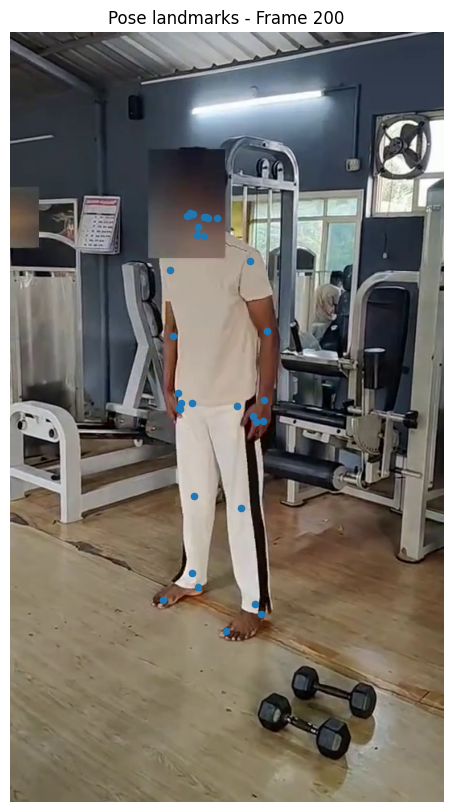

In [26]:
import matplotlib.pyplot as plt
import cv2

# Đọc lại frame giữa video
cap = cv2.VideoCapture(video_path)

frame_index = 200
cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)

ret, frame = cap.read()
cap.release()

# OpenCV BGR -> RGB
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# Keypoints của frame 200
points = keypoints[frame_index]

plt.figure(figsize=(8, 10))
plt.imshow(frame_rgb)

# Vẽ 33 landmarks
plt.scatter(
    points[:, 0] * frame.shape[1],
    points[:, 1] * frame.shape[0],
    s=20
)

plt.title(f"Pose landmarks - Frame {frame_index}")
plt.axis("off")
plt.show()